# Live

Diagrams in real time: background runs paced to the wall clock, at any
speed; live plots and smooth animations while they run; parameter changes
between chunks; samples from other threads, as from a receiver.

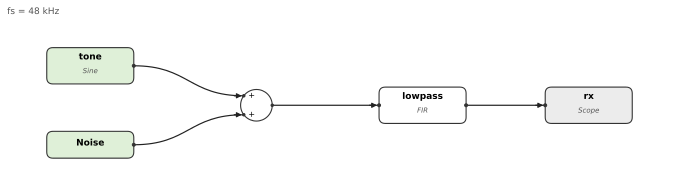

In [1]:
%config InlineBackend.figure_formats = ["svg"]  # crisp at any zoom
import threading
import time

import numpy as np
import scipy.signal as sig

import sigline as sl

fs = 48_000.0
tone = sl.Sine(1e3, name="tone")
rx = sl.Scope("rx", keep=4800)
(
    tone + sl.Noise(0.2, seed=1)
    >> sl.FIR(sig.firwin(101, 3e3, fs=fs), name="lowpass")
    >> rx
)
d = sl.Diagram(rx, fs=fs)
d

## 1. Background runs

`d.start()` returns at once and runs in a thread, paced to the wall clock;
`speed` sets simulated seconds per wall-clock second, `realtime=False` runs
as fast as it can. `d.overruns` counts chunks that finished late.

In [2]:
for kw in ({}, {"speed": 4.0}, {"realtime": False}):
    t0 = time.perf_counter()
    d.reset().start(1.0, **kw).wait()
    print(
        f"1 s of signal, {kw or 'real time'}: {time.perf_counter() - t0:.2f} s, "
        f"overruns {d.overruns}"
    )

1 s of signal, real time: 1.00 s, overruns 0


1 s of signal, {'speed': 4.0}: 0.25 s, overruns 0
1 s of signal, {'realtime': False}: 0.02 s, overruns 0


## 2. Watching a run

`d.watch(T, draw)` starts a paced run and redraws `draw(fig)` while it
runs; read scopes there with `snapshot()` or their plot methods. A timer
retunes the tone after one second with `d.set`, which applies changes
between chunks: the peak moves. In a notebook frames arrive as images, a
few per second; `window=True` draws into a window instead.

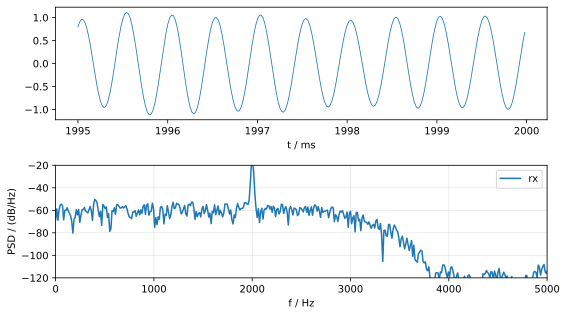

tone now at 2000.0 Hz


In [3]:
def draw(fig):
    a1, a2 = fig.subplots(2, 1)
    t, y = rx.snapshot()
    a1.plot(1e3 * t[-240:], y[-240:], lw=0.8)
    a1.set(xlabel="t / ms")
    rx.plot_psd(ax=a2)
    a2.set(xlim=(0, 5e3), ylim=(-120, -20))
    fig.tight_layout()


d.reset()
tone.f = 1e3
threading.Timer(1.0, d.set, args=(tone,), kwargs={"f": 2e3}).start()
d.watch(2.0, draw, interval=0.25, figsize=(8, 4.5))
print("tone now at", tone.f, "Hz")

## 3. Smooth animation

For animation, `draw` builds the figure once and returns `update()`, which
moves the artists and returns them; a window then redraws only those
(blitting), about 20 frames per second. Here a mass on a spring, released
from 0.1 m, slowed down twofold.

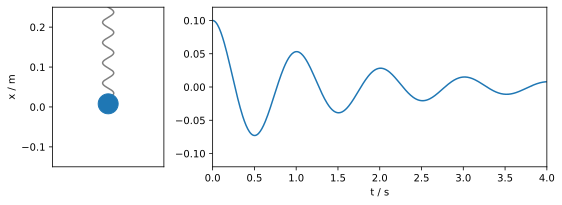

max |error| vs closed form: 9.9e-17 m


In [4]:
f0, zeta = 1.0, 0.1  # natural frequency / Hz, damping
w0 = 2 * np.pi * f0
mass = sl.ContinuousLTI(A=[[0, 1], [-(w0**2), -2 * zeta * w0]], B=[[0], [0]],
                        C=[[1, 0]], D=[[0]], x0=[0.1, 0.0], name="mass")  # fmt: skip
x = sl.Scope("x")
sl.Const(0.0) >> mass >> x
spring = sl.Diagram(x, fs=100.0)


def draw(fig):
    a1, a2 = fig.subplots(1, 2, gridspec_kw={"width_ratios": [1, 3]})
    (coil,) = a1.plot([], [], c="gray")
    (ball,) = a1.plot([], [], "o", ms=20)
    a1.set(xlim=(-1, 1), ylim=(-0.15, 0.25), xticks=[], ylabel="x / m")
    (trace,) = a2.plot([], [])
    a2.set(xlim=(0, 4), ylim=(-0.12, 0.12), xlabel="t / s")
    fig.tight_layout()

    def update():
        t, y = x.snapshot()
        if len(t):
            coil.set_data(0.1 * np.sin(np.linspace(0, 30, 200)),
                          np.linspace(0.25, y[-1], 200))  # fmt: skip
            ball.set_data([0], [y[-1]])
            trace.set_data(t, y)
        return coil, ball, trace

    return update


spring.watch(4.0, draw, speed=2.0, figsize=(8, 3))  # window=True: smooth
t = spring.t
wd = w0 * np.sqrt(1 - zeta**2)
closed = (
    0.1 * np.exp(-zeta * w0 * t) * (np.cos(wd * t) + zeta * w0 / wd * np.sin(wd * t))
)
print(f"max |error| vs closed form: {np.max(np.abs(x.data - closed)):.1e} m")

## 4. Samples from another thread

A simulated receiver pushes blocks of complex samples into a `FromQueue` at
its own pace; the diagram waits for them, so the receiver sets the pace. A
`ToQueue` hands the result to other threads. Device blocks build on this:
`RtlSdrSource`, `AudioIn`, `AudioOut` (optional extras), retuned while
running with `d.set(sdr, center_freq=...)`.

122880 samples, underruns 0, max |y - 1| = 2.9e-11


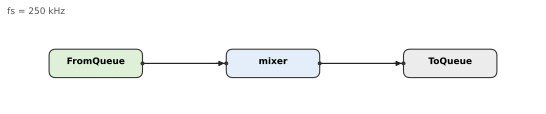

In [5]:
fs_iq, block, n_blocks = 250_000.0, 4096, 30
src, sink = sl.FromQueue(), sl.ToQueue()
src >> sl.mixer(-25e3, "exp") >> sink
d_iq = sl.Diagram(sink, fs=fs_iq)
iq = np.exp(2j * np.pi * 25e3 * np.arange(n_blocks * block) / fs_iq)  # +25 kHz


def receiver():
    for k in range(n_blocks):
        src.push(iq[k * block : (k + 1) * block])
        time.sleep(block / fs_iq)  # real-time delivery


th = threading.Thread(target=receiver)
th.start()
d_iq.start(n=n_blocks * block, chunk=2048).wait()
th.join()
y = sink.pull(n_blocks * block)
err = np.max(np.abs(y - 1))
print(f"{len(y)} samples, underruns {src.underruns}, max |y - 1| = {err:.1e}")
d_iq

## Summary

- `d.start(speed=...)`, `d.stop()`, `d.wait()`: background runs, paced or
  as fast as possible; `d.set` and `d.call` change things between chunks.
- `d.watch(T, draw)`: live plots; a `draw` returning `update()` animates
  smoothly, best with `window=True`.
- `FromQueue`, `ToQueue` and device blocks connect other threads and
  hardware.